# UTS GRAF SAINS DATA

- NAMA: ALIFIYANTI PUTRI NUR AZIZAH
- NIM: 24031554032
- KELAS: 2024B

SPLIT PERIODE: P1 (01–15 Agt 2015) | P2 (01–18 Sept 2015)

## Download Data

In [ ]:
# Mengunduh dataset dari Kaggle dan menyimpannya sebagai ecommerce-dataset.zip
!curl -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0           00:01              0
  0      0   0      0   0      0      0      0           00:01              0
  0      0   0      0   0      0      0      0           00:01              0

  0      0   0      0   0      0      0      0           00:01              0
  2 290.6M   2  6.59M   0      0  2.35M      0   02:03   00:02   02:01  6.58M
  7 290.6M   7 22.26M   0      0  5.86M      0   00:49   00:03   00:46 11.12M
 13 290.6M  13 38.38M   0      0  8.00M      0   00:36   00:04   00:32 12.79M
 18 290.6M  18 54.48M   0      0  9.40M      0   00:30   00:05   00:25 13.62M
 24 290.6M  24 70.62M   0      0 10.39M      0   00:27   00:06   00:21 14.12M
 29 290.6M  29 86.69M   0      0 11.12M      0   00:26   00:07   00:19 16.02M
 35 290.6M  35 102.7M   0      0 11.68M      0   00:24   00:08

## 0. Library dan Konfigurasi

In [1]:
# Jika diperlukan, jalankan sekali di environment notebook:
# %pip install pandas numpy scipy scikit-learn networkx matplotlib neo4j tqdm

from pathlib import Path
import os
import getpass
import math
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase
from tqdm.auto import tqdm

DATA_PATH = Path("events.csv")
NEO4J_URI = os.getenv("NEO4J_URI", "bolt://localhost:7687")
NEO4J_USER = os.getenv("NEO4J_USER", "neo4j")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD") or getpass.getpass("Password Neo4j: ")
NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", "neo4j")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File {DATA_PATH.resolve()} tidak ditemukan. Letakkan events.csv di folder notebook."
    )

print("File data ditemukan:", DATA_PATH.resolve())
print("URI Neo4j:", NEO4J_URI)
print("Database:", NEO4J_DATABASE)

d:\KULYEAH\SEM 5\GRAF SAINS DATA\UTS GRAF SAINS DATA\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


File data ditemukan: D:\KULYEAH\SEM 5\GRAF SAINS DATA\UTS GRAF SAINS DATA\events.csv
URI Neo4j: bolt://localhost:7687
Database: neo4j


## 2.1  Wrangling dan EDA

### Soal 1 - 2

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama!

    P1 (01–15 Agt 2015) | P2 (01–18 Sept 2015)

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [2]:
print("Membaca data RetailRocket...")
df = pd.read_csv(DATA_PATH)
required_cols = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing_cols)}")

# Timestamp sumber adalah Unix epoch dalam milidetik (UTC).
df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
df = df.dropna(subset=["timestamp", "visitorid", "itemid", "event"]).copy()
df["timestamp"] = df["timestamp"].astype("int64")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True).dt.tz_localize(None)

# Pilihan nomor 35:
# P1 = 1–15 Agustus 2015 (tanggal akhir eksklusif: 16 Agustus)
# P2 = 1–18 September 2015 (tanggal akhir eksklusif: 19 September)
P1_START = pd.Timestamp("2015-08-01")
P1_END_EXCLUSIVE = pd.Timestamp("2015-08-16")
P2_START = pd.Timestamp("2015-09-01")
P2_END_EXCLUSIVE = pd.Timestamp("2015-09-19")

p1_train = df.loc[
    (df["datetime"] >= P1_START) & (df["datetime"] < P1_END_EXCLUSIVE)
].copy()
p2_test = df.loc[
    (df["datetime"] >= P2_START) & (df["datetime"] < P2_END_EXCLUSIVE)
].copy()

# Simpan hanya data pada rentang yang ditetapkan.
p1_train.to_csv("events_train_P1.csv", index=False)
p2_test.to_csv("events_test_P2.csv", index=False)

print(f"Rentang data sumber : {df['datetime'].min()} s.d. {df['datetime'].max()}")
print(f"P1 yang dipilih     : {P1_START.date()} s.d. {(P1_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}")
print(f"P2 yang dipilih     : {P2_START.date()} s.d. {(P2_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}")
print(f"Training P1         : {len(p1_train):,} baris")
print(f"Testing P2          : {len(p2_test):,} baris")
print("CSV tersimpan: events_train_P1.csv dan events_test_P2.csv")
print("\nKomposisi event P1:")
display(p1_train["event"].value_counts().rename_axis("event").to_frame("jumlah"))
print("\nKomposisi event P2:")
display(p2_test["event"].value_counts().rename_axis("event").to_frame("jumlah"))

Membaca data RetailRocket...
Rentang data sumber : 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000
P1 yang dipilih     : 2015-08-01 s.d. 2015-08-15
P2 yang dipilih     : 2015-09-01 s.d. 2015-09-18
Training P1         : 265,509 baris
Testing P2          : 303,710 baris
CSV tersimpan: events_train_P1.csv dan events_test_P2.csv

Komposisi event P1:


,jumlah
event,
view,256371
addtocart,7047
transaction,2091



Komposisi event P2:


,jumlah
event,
view,293660
addtocart,7681
transaction,2369


Pada bagian ini, data interaksi dibagi menjadi dua periode yang berbeda. Periode P1 (1–15 Agustus 2015) digunakan sebagai data training, sedangkan periode P2 (1–18 September 2015) digunakan sebagai data testing. Pemfilteran dilakukan pada kolom timestamp yang terlebih dahulu dikonversi dari Unix epoch dalam milidetik menjadi format tanggal dan waktu.

Batas akhir pada kode dibuat eksklusif, yaitu 16 Agustus untuk P1 dan 19 September untuk P2. Dengan demikian, tanggal 15 Agustus dan 18 September tetap masuk ke periode masing-masing. Data yang berada di luar kedua rentang tersebut tidak dimasukkan ke file hasil split. Kedua hasil disimpan sebagai `events_train_P1.csv` dan `events_test_P2.csv`.

Jumlah baris dan komposisi jenis event setiap periode dapat dilihat pada output sel di atas. Angka tersebut mengikuti hasil pemfilteran dari file `events.csv` yang dijalankan, sehingga tidak ditulis sebagai angka tetap di penjelasan ini.

### Soal 3

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [5]:
# Verifikasi koneksi Neo4j
with GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
) as driver:

    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil.")

    with driver.session(database=NEO4J_DATABASE) as session:

        # Hapus node secara bertahap agar penggunaan memori lebih kecil
        total_deleted = 0

        while True:
            result = session.run("""
                MATCH (n:RR_RetailRocket)
                WITH n
                LIMIT 200
                DETACH DELETE n
                RETURN count(n) AS deleted
            """)

            deleted = result.single()["deleted"]
            total_deleted += deleted

            if deleted == 0:
                break

            print(f"Node terhapus: {total_deleted}")

        # Pastikan constraint tersedia
        session.run("""
            CREATE CONSTRAINT rr_visitor_id_unique IF NOT EXISTS
            FOR (v:RRVisitor)
            REQUIRE v.visitorid IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT rr_item_id_unique IF NOT EXISTS
            FOR (i:RRItem)
            REQUIRE i.itemid IS UNIQUE
        """).consume()

        print(f"Total node terhapus: {total_deleted}")
        print("Constraint berhasil diperiksa/dibuat.")


Koneksi Neo4j berhasil.
Node terhapus: 200
Node terhapus: 400
Node terhapus: 600
Node terhapus: 800
Node terhapus: 1000
Node terhapus: 1200
Node terhapus: 1400
Node terhapus: 1600
Node terhapus: 1800
Node terhapus: 2000
Node terhapus: 2200
Node terhapus: 2400
Node terhapus: 2600
Node terhapus: 2800
Node terhapus: 3000
Node terhapus: 3200
Node terhapus: 3400
Node terhapus: 3600
Node terhapus: 3800
Node terhapus: 4000
Node terhapus: 4200
Node terhapus: 4400
Node terhapus: 4600
Node terhapus: 4800
Node terhapus: 5000
Node terhapus: 5200
Node terhapus: 5400
Node terhapus: 5600
Node terhapus: 5800
Node terhapus: 6000
Node terhapus: 6200
Node terhapus: 6400
Node terhapus: 6600
Node terhapus: 6800
Node terhapus: 7000
Node terhapus: 7200
Node terhapus: 7400
Node terhapus: 7600
Node terhapus: 7800
Node terhapus: 8000
Node terhapus: 8200
Node terhapus: 8400
Node terhapus: 8600
Node terhapus: 8800
Node terhapus: 9000
Node terhapus: 9200
Node terhapus: 9400
Node terhapus: 9600
Node terhapus: 9800


In [6]:
def import_batch(tx, rows):
    query = """
    UNWIND $rows AS row
    MERGE (v:RR_RetailRocket:Visitor:RRVisitor {visitorid: row.visitorid})
    MERGE (i:RR_RetailRocket:Item:RRItem {itemid: row.itemid})
    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    )
    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    )
    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    )
    """
    tx.run(query, rows=rows)

# Impor P1 saja agar data testing tidak bocor ke proses pembentukan rekomendasi.
cols_to_import = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
train_import = p1_train[cols_to_import].copy()
train_import["visitorid"] = train_import["visitorid"].astype("int64")
train_import["itemid"] = train_import["itemid"].astype("int64")
train_import["timestamp"] = train_import["timestamp"].astype("int64")
train_import["transactionid"] = train_import["transactionid"].where(train_import["transactionid"].notna(), "").astype(str)

BATCH_SIZE = 5000
with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    driver.verify_connectivity()
    with driver.session(database=NEO4J_DATABASE) as session:
        for start in tqdm(range(0, len(train_import), BATCH_SIZE), desc="Impor P1 ke Neo4j"):
            batch_df = train_import.iloc[start:start + BATCH_SIZE]
            rows = batch_df.to_dict(orient="records")
            session.execute_write(import_batch, rows)

print(f"Impor selesai: {len(train_import):,} baris P1 diproses.")

Impor P1 ke Neo4j: 100%|██████████| 54/54 [00:59<00:00,  1.11s/it]

Impor selesai: 265,509 baris P1 diproses.


In [7]:
composition_query = """
MATCH (n)
WHERE n:RR_RetailRocket AND (n:Visitor OR n:Item)
UNWIND labels(n) AS label
WITH label, count(DISTINCT n) AS jumlah
WHERE label IN ['Visitor', 'Item']
RETURN label, jumlah
ORDER BY label
"""
relationship_query = """
MATCH (v:RR_RetailRocket:Visitor)-[r]->(i:RR_RetailRocket:Item)
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jenis_relasi
"""

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        node_rows = [record.data() for record in session.run(composition_query)]
        rel_rows = [record.data() for record in session.run(relationship_query)]

print("Komposisi node:")
display(pd.DataFrame(node_rows))
print("Komposisi relasi:")
display(pd.DataFrame(rel_rows))

print("\nPenjelasan query: MATCH (n) mencari node, WHERE membatasi pada label Visitor/Item,")
print("UNWIND labels(n) memecah label, dan count(DISTINCT n) menghitung node unik per label.")
print("Query kedua menghitung jumlah relasi interaksi berdasarkan tipe relasi.")

Komposisi node:


,label,jumlah
0,Item,76078
1,Visitor,153836


Komposisi relasi:


,jenis_relasi,jumlah
0,ADDED_TO_CART,6991
1,BOUGHT,2091
2,VIEWED,256361



Penjelasan query: MATCH (n) mencari node, WHERE membatasi pada label Visitor/Item,
UNWIND labels(n) memecah label, dan count(DISTINCT n) menghitung node unik per label.
Query kedua menghitung jumlah relasi interaksi berdasarkan tipe relasi.


Subgraph yang dibangun terdiri dari dua jenis simpul utama, yaitu Visitor dan Item. Simpul Visitor mewakili pengguna yang melakukan interaksi, sedangkan simpul Item mewakili produk yang diakses pengguna. Hubungan di antara keduanya menunjukkan aktivitas pengguna terhadap item.

Query `composition_query` menggunakan `MATCH (n)` untuk mencari node, kemudian `WHERE` membatasi pencarian pada node yang memiliki label `RR_RetailRocket` dan label `Visitor` atau `Item`. Bagian `UNWIND labels(n)` memisahkan label node, sedangkan `count(DISTINCT n)` menghitung node unik untuk setiap jenis. Hasilnya diurutkan berdasarkan nama label.

Query `relationship_query` mencari relasi dari Visitor menuju Item. Fungsi `type(r)` mengambil jenis relasi, seperti `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`, dan `count(r)` menghitung jumlah relasi untuk masing-masing jenis. Kedua query dijalankan melalui Python API Neo4j menggunakan `driver.session()` dan hasilnya dikonversi menjadi DataFrame Pandas agar mudah dibaca.

Jumlah node dan relasi yang sebenarnya ditunjukkan pada tabel output di atas. Data yang diimpor ke Neo4j berasal dari periode P1 saja agar periode P2 tetap menjadi data pengujian.

### Soal 4 - 6

4.  Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Bipartite graph:
- Node User: 1,918; Node Item: 1,869
- Interaksi unik dalam sampel: 1,994

Matriks VSM user-item shape: (1918, 1869); jumlah nilai nonzero: 1,994

Proyeksi User: 1,918 node, 179 edge
Proyeksi Item: 1,869 node, 209 edge
Matriks adjacency User-User shape: (1918, 1918)
Matriks adjacency Item-Item shape: (1869, 1869)


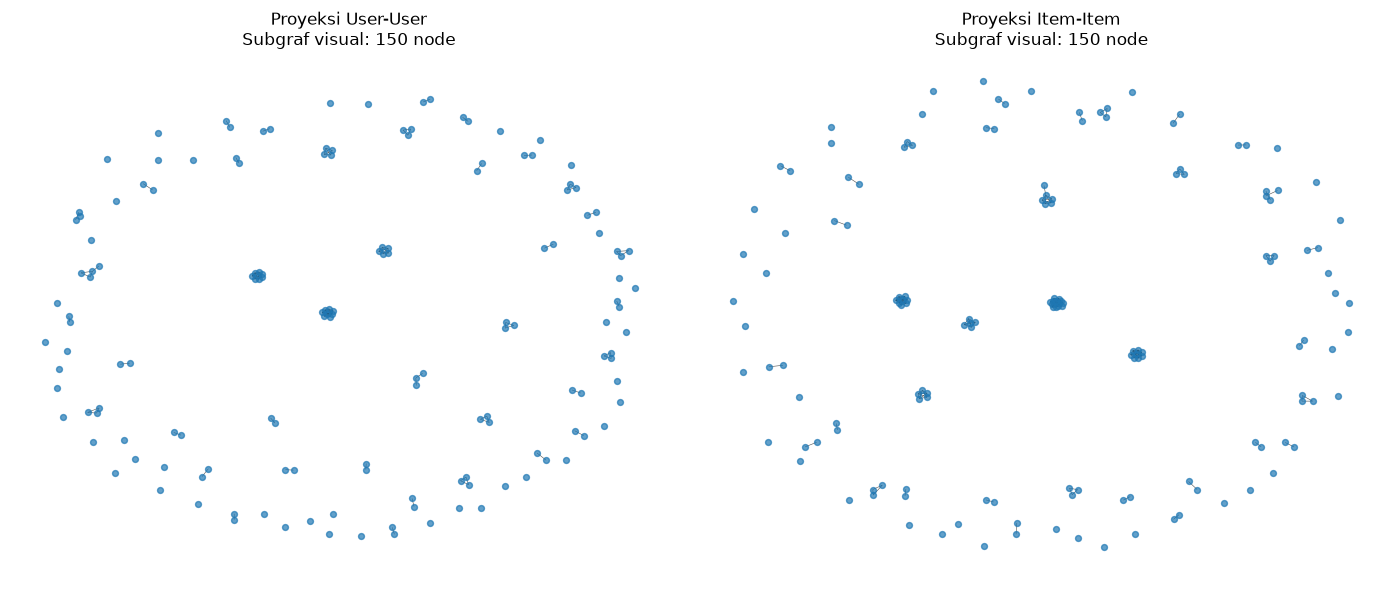

In [8]:
SEED = 42
SAMPLE_N = min(2000, len(p1_train))
sample_df = p1_train.sample(n=SAMPLE_N, random_state=SEED).copy()
sample_pairs = sample_df[["visitorid", "itemid"]].drop_duplicates()

B = nx.Graph()
user_nodes = [f"V_{int(x)}" for x in sample_pairs["visitorid"].unique()]
item_nodes = [f"I_{int(x)}" for x in sample_pairs["itemid"].unique()]
B.add_nodes_from(user_nodes, bipartite=0, node_type="User")
B.add_nodes_from(item_nodes, bipartite=1, node_type="Item")
B.add_edges_from(
    (f"V_{int(v)}", f"I_{int(i)}")
    for v, i in sample_pairs.itertuples(index=False, name=None)
)

users = {n for n, d in B.nodes(data=True) if d["bipartite"] == 0}
items = set(B) - users
user_projection = nx.bipartite.weighted_projected_graph(B, users)
item_projection = nx.bipartite.weighted_projected_graph(B, items)

# Matriks VSM: baris = user, kolom = item; nilai 1 menandakan ada interaksi pada sampel.
user_order = sorted(users)
item_order = sorted(items)
A = nx.bipartite.biadjacency_matrix(B, row_order=user_order, column_order=item_order, dtype=np.uint8, weight=None)

print("Bipartite graph:")
print(f"- Node User: {len(users):,}; Node Item: {len(items):,}")
print(f"- Interaksi unik dalam sampel: {B.number_of_edges():,}")
print(f"\nMatriks VSM user-item shape: {A.shape}; jumlah nilai nonzero: {A.nnz:,}")
print(f"\nProyeksi User: {user_projection.number_of_nodes():,} node, {user_projection.number_of_edges():,} edge")
print(f"Proyeksi Item: {item_projection.number_of_nodes():,} node, {item_projection.number_of_edges():,} edge")
print(f"Matriks adjacency User-User shape: {(len(users), len(users))}")
print(f"Matriks adjacency Item-Item shape: {(len(items), len(items))}")

# Visualisasi ringkas: tampilkan hingga 150 node berderajat tertinggi pada masing-masing proyeksi.
def plot_projection(G, title, ax, max_nodes=150):
    if G.number_of_nodes() == 0:
        ax.set_title(title + " (kosong)")
        ax.axis("off")
        return
    chosen = sorted(G.degree, key=lambda x: x[1], reverse=True)[:max_nodes]
    H = G.subgraph([n for n, _ in chosen]).copy()
    pos = nx.spring_layout(H, seed=SEED, k=None)
    nx.draw_networkx(H, pos=pos, ax=ax, with_labels=False, node_size=18, width=0.4, alpha=0.7)
    ax.set_title(f"{title}\nSubgraf visual: {H.number_of_nodes()} node")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_projection(user_projection, "Proyeksi User-User", axes[0])
plot_projection(item_projection, "Proyeksi Item-Item", axes[1])
plt.tight_layout()
plt.show()

Untuk membentuk VSM, data P1 diambil menggunakan sampel acak maksimal 2.000 baris dengan `random_state=42`, sehingga proses sampling dapat direproduksi. Pasangan `visitorid` dan `itemid` yang duplikat dihilangkan, lalu dibuat graf bipartit: simpul User dan Item berada pada dua kelompok berbeda, dan edge menunjukkan adanya interaksi di antara keduanya.

VSM User direpresentasikan oleh matriks biadjacency `A`, dengan baris sebagai User dan kolom sebagai Item. Nilai 1 menunjukkan bahwa pasangan User–Item tersebut memiliki interaksi pada sampel. Karena itu, bentuk matriksnya adalah `(jumlah User, jumlah Item)`. Banyaknya nilai nonzero `(A.nnz)` menunjukkan jumlah pasangan interaksi unik yang tersimpan.

VSM Item dapat dipahami melalui proyeksi Item–Item. Dua simpul Item dihubungkan jika keduanya memiliki keterkaitan melalui User yang sama. Bobot edge pada proyeksi ini menunjukkan banyaknya tetangga bersama pada graf bipartit. Matriks adjacency proyeksi User–User berbentuk `(jumlah User, jumlah User)`, sedangkan proyeksi Item–Item berbentuk `(jumlah Item, jumlah Item)`.

Plot NetworkX memperlihatkan subgraf ringkas dari masing-masing proyeksi. Untuk menjaga visualisasi tetap terbaca, kode hanya menggambar hingga 150 node dengan derajat tertinggi pada setiap proyeksi dan tidak menampilkan label node. Oleh karena itu, plot merupakan gambaran bagian graf, bukan seluruh simpul pada proyeksi. Jumlah node, edge, serta shape matriks lengkap dapat dilihat dari output sel.

### Soal 6

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Jawab:

Untuk sistem rekomendasi pada notebook ini, proyeksi Item-Item dipilih karena rekomendasi dibentuk dari item yang pernah diinteraksi user pada P1, kemudian mencari item lain dengan pola pengunjung yang mirip. Pemilihan ini sesuai dengan pendekatan item-based collaborative filtering.

Keputusan efisiensi harus dilihat dari angka hasil sel sebelumnya: jumlah node, edge, dan ukuran matriks. Jangan menyatakan proyeksi Item selalu lebih kecil/lebih efisien tanpa memeriksa hasil. Visualisasi hanya menampilkan subgraf node berderajat tinggi agar mudah dibaca; ukuran graf penuh sampel tetap dicetak.

### Soal 7

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

    a.  Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

    b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [9]:
N_CATALOG = min(500, p1_train["itemid"].nunique())
TOP_NEIGHBORS = 5

popular_item_ids = (
    p1_train.groupby("itemid").size().sort_values(ascending=False).head(N_CATALOG).index.astype("int64").tolist()
)
item_to_row = {int(item_id): idx for idx, item_id in enumerate(popular_item_ids)}
filtered = p1_train.loc[p1_train["itemid"].isin(popular_item_ids), ["visitorid", "itemid"]].drop_duplicates()
visitor_ids = filtered["visitorid"].drop_duplicates().astype("int64").tolist()
visitor_to_col = {int(visitor_id): idx for idx, visitor_id in enumerate(visitor_ids)}

row_idx = filtered["itemid"].astype("int64").map(item_to_row).to_numpy()
col_idx = filtered["visitorid"].astype("int64").map(visitor_to_col).to_numpy()
item_user_matrix = sp.csr_matrix(
    (np.ones(len(filtered), dtype=np.float32), (row_idx, col_idx)),
    shape=(len(popular_item_ids), len(visitor_ids)),
    dtype=np.float32,
)
item_user_matrix.data[:] = 1.0

# Hasil similarity hanya 500 x 500, bukan matriks dense 235k x 235k.
item_sim = cosine_similarity(item_user_matrix, dense_output=True)
item_ids = [int(x) for x in popular_item_ids]
print(f"Katalog item: {len(item_ids):,}")
print(f"Matriks item-user shape: {item_user_matrix.shape}; nonzero: {item_user_matrix.nnz:,}")
print(f"Matriks cosine similarity shape: {item_sim.shape}")

# Ambil item acuan yang memiliki tetangga positif terbanyak; deterministic dari katalog terurut.
positive_neighbor_counts = ((item_sim > 0).sum(axis=1) - 1)
anchor_idx = int(np.argmax(positive_neighbor_counts))
anchor_item = item_ids[anchor_idx]
sim_scores = item_sim[anchor_idx].copy()
sim_scores[anchor_idx] = -1.0
similar_indices = [int(i) for i in np.argsort(sim_scores)[::-1] if sim_scores[i] > 0][:5]

print(f"\nItem acuan: {anchor_item}")
if similar_indices:
    top_similar = pd.DataFrame({
        "item_acuan": anchor_item,
        "item_mirip": [item_ids[i] for i in similar_indices],
        "cosine_similarity": [float(sim_scores[i]) for i in similar_indices],
    })
    display(top_similar)
else:
    top_similar = pd.DataFrame(columns=["item_acuan", "item_mirip", "cosine_similarity"])
    print("Tidak ditemukan item lain dengan similarity positif pada katalog ini.")

Katalog item: 500
Matriks item-user shape: (500, 20184); nonzero: 23,903
Matriks cosine similarity shape: (500, 500)

Item acuan: 461686


,item_acuan,item_mirip,cosine_similarity
0,461686,218794,0.369587
1,461686,171878,0.364938
2,461686,10572,0.212709
3,461686,119736,0.103271
4,461686,183758,0.085868


In [10]:
similarity_rows = []
for i, item_id in enumerate(item_ids):
    scores = item_sim[i].copy()
    scores[i] = -1.0  # item tidak boleh menjadi tetangga dirinya sendiri
    neighbor_idx = [int(j) for j in np.argsort(scores)[::-1] if scores[j] > 0][:TOP_NEIGHBORS]
    for j in neighbor_idx:
        similarity_rows.append({
            "item1": int(item_id),
            "item2": int(item_ids[j]),
            "score": float(scores[j]),
        })

print(f"Relasi SIMILAR_TO yang akan disimpan: {len(similarity_rows):,}")

def insert_similarity_batch(tx, rows):
    query = """
    UNWIND $rows AS row
    MATCH (i1:RR_RetailRocket:Item {itemid: row.item1})
    MATCH (i2:RR_RetailRocket:Item {itemid: row.item2})
    MERGE (i1)-[r:SIMILAR_TO]->(i2)
    SET r.score = row.score
    """
    tx.run(query, rows=rows)

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    driver.verify_connectivity()
    with driver.session(database=NEO4J_DATABASE) as session:
        for start in tqdm(range(0, len(similarity_rows), 1000), desc="Simpan similarity"):
            session.execute_write(insert_similarity_batch, similarity_rows[start:start + 1000])

print("Similarity berhasil disimpan.")

# Cypher untuk memperoleh top 5 tetangga dari item acuan.
top5_query = """
MATCH (i1:RR_RetailRocket:Item {itemid: $anchor_item})-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item_acuan, i2.itemid AS item_mirip, r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        top5_records = [r.data() for r in session.run(top5_query, anchor_item=int(anchor_item))]

display(pd.DataFrame(top5_records))
print("Cypher yang digunakan:")
print(top5_query)

Relasi SIMILAR_TO yang akan disimpan: 2,064


Simpan similarity: 100%|██████████| 3/3 [00:01<00:00,  1.83it/s]


Similarity berhasil disimpan.


,item_acuan,item_mirip,similarity
0,461686,218794,0.369587
1,461686,171878,0.364938
2,461686,10572,0.212709
3,461686,119736,0.103271
4,461686,183758,0.085868


Cypher yang digunakan:

MATCH (i1:RR_RetailRocket:Item {itemid: $anchor_item})-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item_acuan, i2.itemid AS item_mirip, r.score AS similarity
ORDER BY similarity DESC
LIMIT 5



Similarity antar-item dihitung menggunakan cosine similarity berdasarkan pola interaksi User–Item pada periode P1. Matriks `item_user_matrix` memiliki baris sebagai item dan kolom sebagai visitor; nilai 1 menunjukkan bahwa visitor berinteraksi dengan item tersebut. Agar perhitungan tidak terlalu berat, proses dibatasi pada maksimal 500 item terpopuler di P1. Matriks similarity yang dihasilkan memiliki bentuk `(jumlah item katalog, jumlah item katalog)`.

Untuk setiap item, kode mencari maksimal lima item lain dengan skor cosine similarity positif tertinggi. Item tidak dibandingkan dengan dirinya sendiri. Item acuan dipilih secara deterministik dari katalog berdasarkan jumlah tetangga yang memiliki similarity positif, sehingga hasil pemilihan dapat direproduksi dari data yang sama.

Nilai similarity kemudian disimpan ke Neo4j sebagai relasi berarah `SIMILAR_TO` dengan properti `score`. Query Cypher pada sel berikutnya mengambil lima tetangga dari item acuan, mengurutkannya berdasarkan `r.score` dari nilai tertinggi ke terendah, lalu membatasi hasil dengan `LIMIT 5`. Tabel output menampilkan item acuan, item yang mirip, dan nilai similarity-nya.

Skor yang semakin mendekati 1 menunjukkan pola interaksi item yang semakin mirip pada representasi yang digunakan. Nilai yang diperoleh dan identitas item mengikuti tabel hasil eksekusi notebook.

### Soal 8

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [11]:
before_query = """
MATCH (v:RR_RetailRocket:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:RR_RetailRocket:Item)
RETURN v.visitorid AS visitorid, type(r) AS event, i.itemid AS itemid
LIMIT 30
"""
after_query = """
MATCH (i1:RR_RetailRocket:Item)-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item1, r.score AS score, i2.itemid AS item2
ORDER BY score DESC
LIMIT 30
"""

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        before_rows = [record.data() for record in session.run(before_query)]
        after_rows = [record.data() for record in session.run(after_query)]
        rel_counts = [record.data() for record in session.run(
            "MATCH (a:RR_RetailRocket)-[r]->(b:RR_RetailRocket) "
            "RETURN type(r) AS tipe, count(r) AS jumlah ORDER BY tipe"
        )]

print("Contoh relasi interaksi (sebelum similarity):", len(before_rows), "record")
display(pd.DataFrame(before_rows))
print("\nContoh relasi SIMILAR_TO (sesudah similarity):", len(after_rows), "record")
display(pd.DataFrame(after_rows))
print("\nJumlah relasi di database:")
display(pd.DataFrame(rel_counts))

Contoh relasi interaksi (sebelum similarity): 30 record


,visitorid,event,itemid
0,448926,VIEWED,249560
1,918931,VIEWED,249560
2,89809,VIEWED,249560
3,898162,VIEWED,249560
4,636291,VIEWED,249560
5,370960,VIEWED,249560
6,1181103,VIEWED,249560
7,1181103,VIEWED,249560
8,172697,VIEWED,249560
9,522004,VIEWED,188830



Contoh relasi SIMILAR_TO (sesudah similarity): 30 record


,item1,score,item2
0,218794,0.582325,171878
1,171878,0.582325,218794
2,310944,0.496292,393111
3,393111,0.496292,310944
4,243355,0.427352,375822
5,375822,0.427352,243355
6,183087,0.424264,178274
7,178274,0.424264,183087
8,97307,0.413585,222888
9,222888,0.413585,97307



Jumlah relasi di database:


,tipe,jumlah
0,ADDED_TO_CART,6991
1,BOUGHT,2091
2,SIMILAR_TO,2064
3,VIEWED,256361


Sebelum similarity dihitung, graf berisi relasi interaksi antara Visitor dan Item, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Query `before_query` menampilkan contoh interaksi dengan mengembalikan ID visitor, tipe event, dan ID item. Hasil dibatasi hingga 30 record agar mudah diperiksa.

Sesudah perhitungan similarity, relasi `SIMILAR_TO` ditambahkan di antara simpul Item. Properti `score` pada relasi menyimpan nilai cosine similarity. Query `after_query` menampilkan ID item pertama, nilai similarity, dan ID item kedua, kemudian mengurutkan hasil dari skor tertinggi. Query tambahan menghitung jumlah setiap tipe relasi yang ada di database.

Dengan membandingkan hasil tersebut, perubahan utama pada graf adalah bertambahnya relasi Item–Item `SIMILAR_TO` di samping relasi interaksi Visitor–Item yang sudah ada. Tabel di atas menunjukkan contoh record dan jumlah relasi yang benar-benar tersimpan setelah notebook dijalankan.

## 2.2 Analytics

### Soal 1

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

    (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

    (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [12]:
RANDOM_SEED = 42
K = 5
rng = random.Random(RANDOM_SEED)

p1_user_items = p1_train.groupby("visitorid")["itemid"].apply(lambda s: set(map(int, s.unique())))
p2_user_items = p2_test.groupby("visitorid")["itemid"].apply(lambda s: set(map(int, s.unique())))
catalog_set = set(item_ids)

eligible_users = sorted(
    int(user_id) for user_id in (set(p1_user_items.index) & set(p2_user_items.index))
    if len(p1_user_items.loc[user_id] & catalog_set) > 0 and len(p2_user_items.loc[user_id]) > 0
)
if not eligible_users:
    raise ValueError("Tidak ada user yang memenuhi syarat untuk evaluasi P1/P2 dengan katalog terpilih.")

target_user = rng.choice(eligible_users)
seen_items = p1_user_items.loc[target_user]
actual_test_items = p2_user_items.loc[target_user]
seen_catalog_items = seen_items & catalog_set

# Item-based KNN: skor kandidat adalah jumlah similarity terhadap seluruh item katalog
# yang pernah dilihat user pada P1. Data P2 hanya dipakai setelah rekomendasi selesai.
recommendation_scores = {}
for seen_item in seen_catalog_items:
    idx = item_to_row.get(int(seen_item))
    if idx is None:
        continue
    scores = item_sim[idx]
    for j, score in enumerate(scores):
        candidate = item_ids[j]
        if candidate in seen_items or candidate == int(seen_item) or score <= 0:
            continue
        recommendation_scores[candidate] = recommendation_scores.get(candidate, 0.0) + float(score)

ranked_recommendations = sorted(recommendation_scores.items(), key=lambda x: (-x[1], x[0]))
recommendations = [int(item_id) for item_id, score in ranked_recommendations[:K]]

print(f"Seed pemilihan user: {RANDOM_SEED}")
print(f"User terpilih: {target_user}")
print(f"Jumlah item unik pada P1: {len(seen_items):,}")
print(f"Jumlah item unik pada P2 (ground truth): {len(actual_test_items):,}")
print("\nTop rekomendasi (maksimal 5):")
recommendation_table = pd.DataFrame([
    {"rank": rank, "itemid": item_id, "score_agregat_similarity": score}
    for rank, (item_id, score) in enumerate(ranked_recommendations[:K], start=1)
])
display(recommendation_table)

print("Tiga item pertama yang diiklankan:")
for rank, item_id in enumerate(recommendations[:3], start=1):
    print(f"Iklan {rank}: Item {item_id}")
if not recommendations:
    print("Tidak ada kandidat rekomendasi positif untuk user ini; laporkan apa adanya, jangan menambahkan item dummy.")

Seed pemilihan user: 42
User terpilih: 1389135
Jumlah item unik pada P1: 1
Jumlah item unik pada P2 (ground truth): 1

Top rekomendasi (maksimal 5):


,rank,itemid,score_agregat_similarity
0,1,176995,0.033333
1,2,244027,0.031623
2,3,295299,0.026261


Tiga item pertama yang diiklankan:
Iklan 1: Item 176995
Iklan 2: Item 244027
Iklan 3: Item 295299


User dipilih secara acak dari daftar user yang memiliki interaksi pada P1 dan P2, dengan menggunakan `random.Random(42)`. Penggunaan seed 42 membuat pemilihan user dapat direproduksi selama data dan urutan kandidatnya sama. User yang dipilih juga harus memiliki item pada P1 yang termasuk dalam katalog item yang dipakai untuk menghitung similarity, serta memiliki interaksi pada P2 untuk keperluan evaluasi.

Rekomendasi dibuat menggunakan pendekatan item-based KNN. Sistem mengambil item yang pernah diinteraksikan oleh user pada P1, kemudian menjumlahkan skor similarity item-item tersebut terhadap kandidat lain di dalam katalog. Item yang sudah pernah dilihat user pada P1 tidak direkomendasikan kembali. Kandidat diurutkan berdasarkan skor agregat similarity tertinggi, dengan ID item sebagai pemecah seri, lalu diambil maksimal lima item.

Tabel output memperlihatkan daftar rekomendasi teratas untuk user terpilih. Tiga item pertama pada tabel itulah yang dilaporkan sebagai tiga item yang direkomendasikan. Data P2 hanya digunakan sebagai ground truth untuk evaluasi setelah rekomendasi dibuat, bukan untuk membentuk skor rekomendasi, sehingga mengurangi risiko kebocoran data testing.

### Soal 2

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

    (a) Hit@5

    (b) NDCG@5

In [14]:
relevant_items = set(map(int, actual_test_items))
recommended_top_k = recommendations[:K]

# Hit@5: ada minimal satu item rekomendasi yang relevan pada testing.
hit_at_5 = int(any(item in relevant_items for item in recommended_top_k))

# DCG@5 untuk relevansi biner.
dcg_at_5 = sum(
    1.0 / math.log2(rank + 1)
    for rank, item in enumerate(recommended_top_k, start=1)
    if item in relevant_items
)

# IDCG berdasarkan jumlah item relevan yang dapat ditempatkan pada top-K.
ideal_relevant_count = min(len(relevant_items), K)
idcg_at_5 = sum(1.0 / math.log2(rank + 1) for rank in range(1, ideal_relevant_count + 1))
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

hits_list = [item for item in recommended_top_k if item in relevant_items]
print("User:", target_user)
print("Rekomendasi top-K:", recommended_top_k)
print("Item relevan pada testing:", sorted(relevant_items))
print("Item relevan yang ditemukan:", hits_list)
print(f"Hit@5  = {hit_at_5}")
print(f"DCG@5  = {dcg_at_5:.4f}")
print(f"IDCG@5 = {idcg_at_5:.4f}")
print(f"NDCG@5 = {ndcg_at_5:.4f}")

print("\nCatatan interpretasi:")
print("- Hit@5 = 1 berarti setidaknya satu item testing ditemukan di top-5; 0 berarti tidak ada.")
print("- NDCG@5 mendekati 1 bila item relevan berada di posisi atas.")
print("- Jika tidak ada item relevan di testing atau rekomendasi kosong, NDCG@5 dilaporkan 0.")

User: 1389135
Rekomendasi top-K: [176995, 244027, 295299]
Item relevan pada testing: [112612]
Item relevan yang ditemukan: []
Hit@5  = 0
DCG@5  = 0.0000
IDCG@5 = 1.0000
NDCG@5 = 0.0000

Catatan interpretasi:
- Hit@5 = 1 berarti setidaknya satu item testing ditemukan di top-5; 0 berarti tidak ada.
- NDCG@5 mendekati 1 bila item relevan berada di posisi atas.
- Jika tidak ada item relevan di testing atau rekomendasi kosong, NDCG@5 dilaporkan 0.


Evaluasi dilakukan dengan membandingkan maksimal lima item rekomendasi dengan item yang benar-benar diinteraksikan oleh user pada periode P2. Item P2 diperlakukan sebagai item relevan (ground truth).

Hit@5 bernilai 1 jika setidaknya ada satu item relevan pada daftar rekomendasi top-5, dan bernilai 0 jika tidak ada item relevan yang ditemukan. Metrik ini hanya menilai apakah ada rekomendasi yang cocok, bukan posisi item tersebut.

NDCG@5 menilai keberadaan sekaligus posisi item relevan. Item relevan pada peringkat lebih tinggi memberi kontribusi lebih besar melalui diskon logaritmik. Nilai DCG aktual dibagi dengan IDCG, yaitu nilai ideal jika item-item relevan ditempatkan pada urutan teratas. NDCG berada pada rentang 0 sampai 1; nilai yang lebih tinggi menunjukkan item relevan lebih baik posisinya di daftar rekomendasi.

Nilai akhir Hit@5, DCG@5, IDCG@5, dan NDCG@5 ditampilkan oleh output sel. Interpretasi hasil perlu mengikuti angka yang muncul saat notebook dijalankan; jika tidak ada item relevan yang ditemukan, Hit@5 bernilai 0 dan NDCG@5 juga dilaporkan 0 sesuai implementasi kode.